In [1]:
import numpy as np
import fpw
import pandas as pd
import matplotlib.pyplot as plt

165623238.75744057


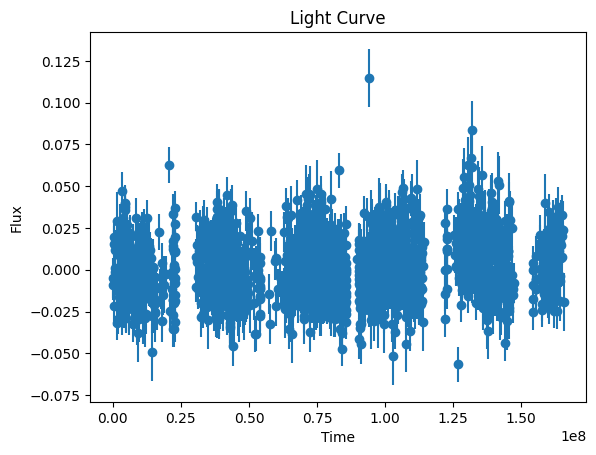

In [ ]:
data_file = '../data/tydy.csv'
data = pd.read_csv(data_file, header=None).to_numpy()
times = data[:, 0]
flux = data[:, 1]
flux_err = data[:, 2]
print(times[-1]/86400)

plt.figure()
plt.errorbar(times, flux, yerr=flux_err, fmt='o')
plt.xlabel('Time')
plt.ylabel('Flux')
plt.title('Light Curve')
plt.show()

fgrid_file = '../data/fgrid.csv'
fgrid = pd.read_csv(fgrid_file, header=None).to_numpy().flatten()

fpw_pgram = fpw.run_fpw(times, flux, flux_err, fgrid, 20)

In [3]:
#Make the FPW pgram into a dataframe and save it as a csv
fpw_df = pd.DataFrame(fpw_pgram)
fpw_df.to_csv('../data/CPU_periodogram.csv', index=False, header=False)

[44.66485365 47.56414758 42.37941599 43.94024443 48.09821763 41.62355904
 45.49955609 44.68953271 47.2135424  41.14752341]


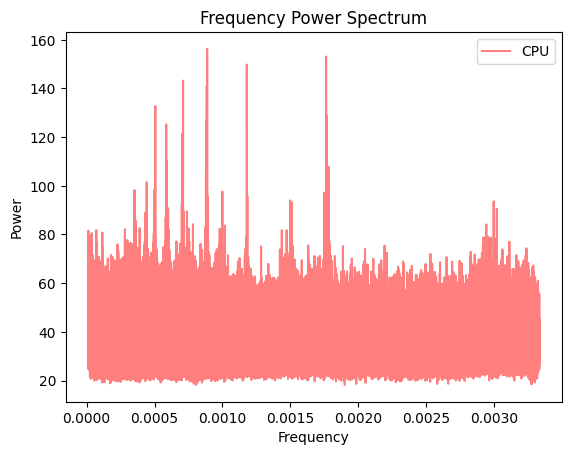

Number of identical consecutive values in FPW Random Periodogram: 764985
Number of identical consecutive frequencies in fgrid: 764985
Fraction of identical consecutive values in FPW Random Periodogram: 0.5400525661471471


In [5]:
print(fpw_pgram[0:10])

fgrid_file = '../data/fgrid.csv'
fgrid = pd.read_csv(fgrid_file, header=None).to_numpy().flatten()

cpu_pgram_file = '../data/CPU_periodogram.csv'
cpu_pgram = pd.read_csv(cpu_pgram_file, header=None).to_numpy().flatten()

# gpu_pgram_file = './data/GPU_periodogram.csv'
# gpu_pgram = pd.read_csv(gpu_pgram_file, header=None).to_numpy().flatten()

# residuals = gpu_pgram - cpu_pgram

plt.figure()
# plt.plot(fgrid, gpu_pgram, label='GPU', color='blue', alpha=0.5)
plt.plot(fgrid, cpu_pgram, label='CPU', color='red', alpha=0.5)
# plt.plot(fgrid, residuals, label='GPU - CPU', color='green', alpha=0.5)
plt.legend()
plt.xlabel('Frequency')
plt.ylabel('Power')
plt.title('Frequency Power Spectrum')
plt.show()

# plt.figure()
# plt.hist(residuals, bins=100)
# plt.xlabel('Residuals')
# plt.ylabel('Count')
# plt.title('Residuals Histogram')
# plt.show()

#Print how many points are identical to their neighbor
identical_count = np.sum(np.diff(cpu_pgram) == 0)
identical_freqs = np.sum(np.diff(fgrid) == 0)
print(f'Number of identical consecutive values in FPW Random Periodogram: {identical_count}')
print(f'Number of identical consecutive frequencies in fgrid: {identical_freqs}')
print(f'Fraction of identical consecutive values in FPW Random Periodogram: {identical_count / len(cpu_pgram)}')

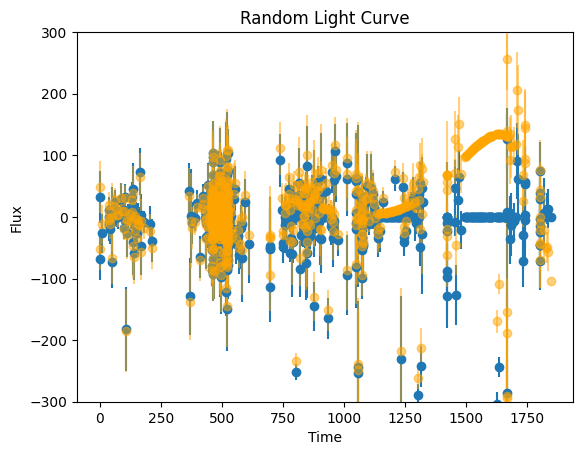

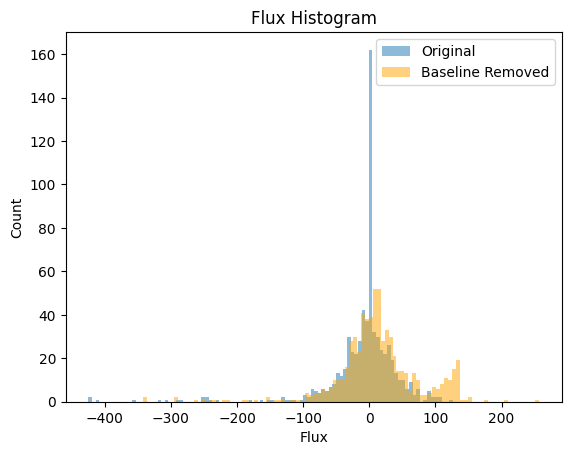

Mean of Original Flux: 0.0
Mean of Baseline Removed Flux: 8.968403816
Standard Deviation of Original Flux: 57.685539516231444
Standard Deviation of Baseline Removed Flux: 65.73023585231327


In [2]:
random_lc_file = '../../build/last_source_lc.csv'
random_lc = pd.read_csv(random_lc_file, header=None).to_numpy()

plt.figure()
plt.errorbar(random_lc[:, 0], random_lc[:, 1], yerr=np.abs(random_lc[:, 2]), fmt='o')
plt.errorbar(random_lc[:, 0], random_lc[:, 3], yerr=np.abs(random_lc[:, 2]), fmt='o', alpha=0.5, color='orange')
plt.xlabel('Time')
plt.ylabel('Flux')
plt.title('Random Light Curve')
plt.ylim(-300, 300)
plt.show()

plt.figure()
plt.hist(random_lc[:, 1], bins=100, alpha=0.5, label='Original')
plt.hist(random_lc[:, 3], bins=100, alpha=0.5, label='Baseline Removed', color='orange')
plt.xlabel('Flux')
plt.ylabel('Count')
plt.title('Flux Histogram')
plt.legend()
plt.show()

mean_original = np.median(random_lc[:, 1])
mean_baseline_removed = np.median(random_lc[:, 3])
print(f'Mean of Original Flux: {mean_original}')
print(f'Mean of Baseline Removed Flux: {mean_baseline_removed}')

std_original = np.std(random_lc[:, 1])
std_baseline_removed = np.std(random_lc[:, 3])
print(f'Standard Deviation of Original Flux: {std_original}')
print(f'Standard Deviation of Baseline Removed Flux: {std_baseline_removed}')

In [4]:
random_pgram_file = '../../build/last_source_periodogram.csv'
random_pgram = pd.read_csv(random_pgram_file, header=None).to_numpy()

fgrid = random_pgram[:, 0]
power = random_pgram[:, 1]

#Run fpw on our random light curve
fpw_random_pgram = fpw.run_fpw(random_lc[:, 0], random_lc[:, 3], random_lc[:, 2], fgrid, 20)

/data/swhitebook/miniconda3/envs/zvar/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


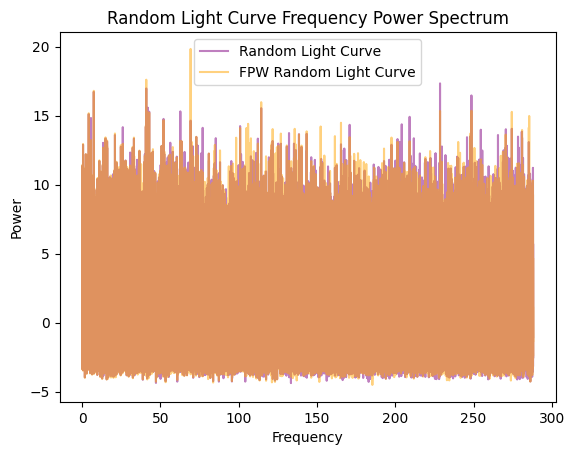

In [5]:
random_pgram_median = np.nanmedian(fpw_random_pgram)
random_pgram_mad = np.nanmedian(np.abs(fpw_random_pgram - random_pgram_median))

random_pgram_power = (fpw_random_pgram - random_pgram_median) / random_pgram_mad

plt.figure()
plt.plot(fgrid, power, label='Random Light Curve', color='purple', alpha=0.5)
plt.plot(fgrid, random_pgram_power, label='FPW Random Light Curve', color='orange', alpha=0.5)
plt.xlabel('Frequency')
plt.ylabel('Power')
plt.title('Random Light Curve Frequency Power Spectrum')
plt.legend()
plt.show()

In [6]:
#Count the nan values in the fpw random pgram
nan_count = np.sum(np.isnan(fpw_random_pgram))
print(f'Number of NaN values in FPW Random Periodogram: {nan_count}')

#Find the indices of the NaN values in the fpw random pgram
nan_indices = np.where(np.isnan(fpw_random_pgram))[0]
print(f'Indices of NaN values in FPW Random Periodogram: {nan_indices}')

nan_median = np.nanmedian(fpw_random_pgram)
print(f'Median of FPW Random Periodogram (excluding NaNs): {nan_median}')
nan_mad = np.nanmedian(np.abs(fpw_random_pgram - nan_median))
print(f'Median Absolute Deviation of FPW Random Periodogram (excluding NaNs): {nan_mad}')

#Count how many values are identical to a value next to it
identical_count = np.sum(np.diff(power) == 0)
print(f'Number of identical consecutive values in FPW Random Periodogram: {identical_count}')

Number of NaN values in FPW Random Periodogram: 5
Indices of NaN values in FPW Random Periodogram: [   0  372  568  809 1332]
Median of FPW Random Periodogram (excluding NaNs): 89.42131694970786
Median Absolute Deviation of FPW Random Periodogram (excluding NaNs): 15.745099761017613
Number of identical consecutive values in FPW Random Periodogram: 0


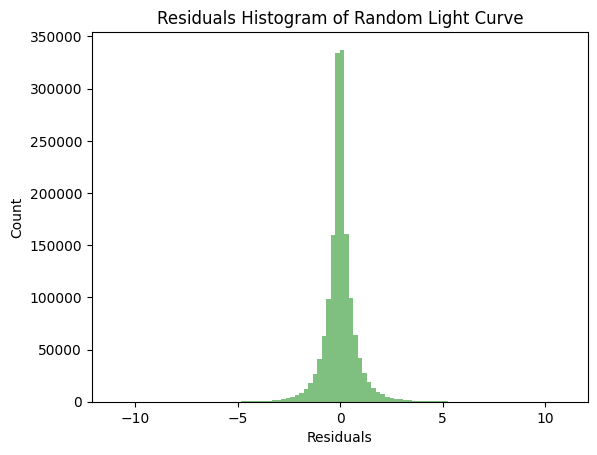

In [7]:
#Subtract the two periodograms and plot the histogram of the residuals
residuals = random_pgram_power - power
plt.figure()
plt.hist(residuals, bins=100, alpha=0.5, color='green')
plt.xlabel('Residuals')
plt.ylabel('Count')
plt.title('Residuals Histogram of Random Light Curve')
plt.show()

In [8]:
#Load in the peaks
peaks_file = '../../build/last_source_peaks.csv'
peaks = pd.read_csv(peaks_file, header=None).to_numpy()

indices = peaks[:, 0]
vals = peaks[:, 1]

max_index = np.argmax(power)
max_value = np.max(power)

print(f'Maximum value in power spectrum: {max_index} with value {max_value}')
print(f'Top peak index from GPU: {indices[0]} with value {vals[0]}')

Maximum value in power spectrum: 1258718 with value 17.34627533
Top peak index from GPU: 1258718.0 with value 17.34627533


<ErrorbarContainer object of 3 artists>

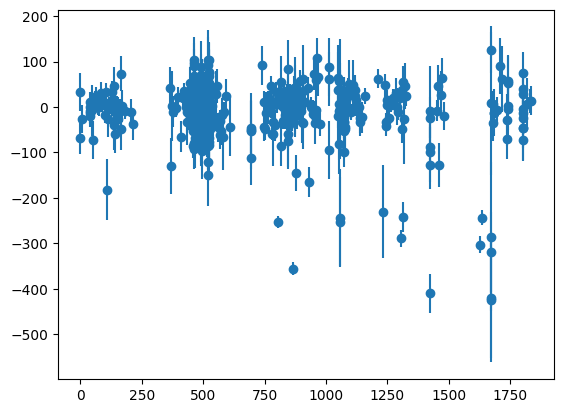

In [9]:
random_lc_file = '../../build/last_source_lc.csv'
random_lc = pd.read_csv(random_lc_file, header=None).to_numpy()

times = random_lc[:, 0]
flux = random_lc[:, 1]
flux_err = random_lc[:, 2]
valid = np.isfinite(flux) & np.isfinite(flux_err)
times = times[valid]
flux = flux[valid]
flux_err = flux_err[valid]


plt.figure()
plt.errorbar(times, flux, flux_err, fmt='o')